In [1]:
! pip install -q opencv-python

In [2]:
! python --version

Python 3.13.18


In [7]:
import cv2 as cv

In [13]:
import cv2 as cv

image = cv.imread('/image.jpg')

array([[[ 52,  42,  65],
        [ 52,  42,  65],
        [ 52,  41,  67],
        ...,
        [ 35,  32,  34],
        [ 38,  35,  37],
        [ 41,  38,  40]],

       [[ 53,  43,  66],
        [ 53,  42,  68],
        [ 53,  42,  68],
        ...,
        [ 35,  32,  34],
        [ 38,  35,  37],
        [ 41,  38,  40]],

       [[ 54,  43,  69],
        [ 54,  43,  69],
        [ 54,  42,  70],
        ...,
        [ 37,  34,  36],
        [ 39,  36,  38],
        [ 42,  39,  41]],

       ...,

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]],

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]],

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]]], shape=(408, 612, 3), dtype=uint8)
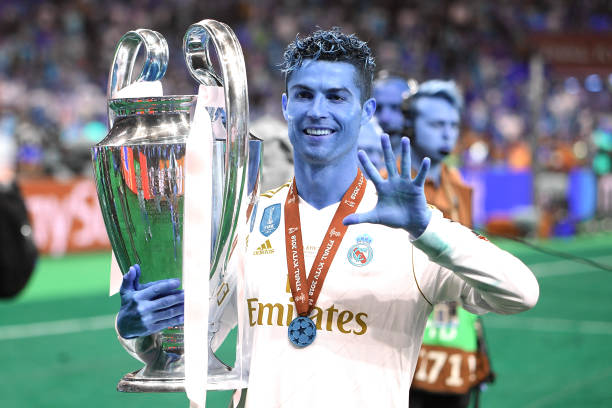

In [14]:
image

In [16]:
type( image)

numpy.ndarray

In [18]:
image.shape

(408, 612, 3)

In [19]:
image.nbytes

749088

In [21]:
image.nbytes / 1024 / 1024

0.714385986328125

In [22]:
from google.colab.patches import cv2_imshow

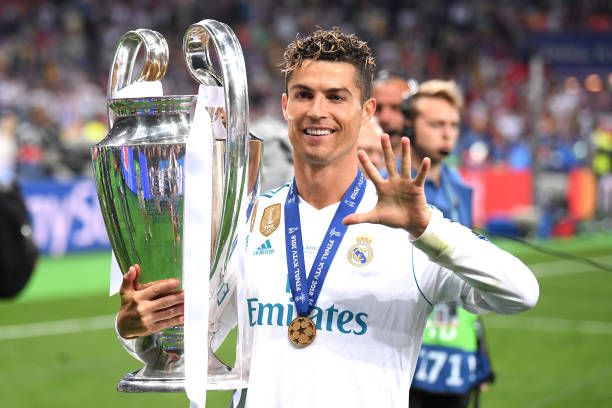

In [23]:
cv2_imshow(image)

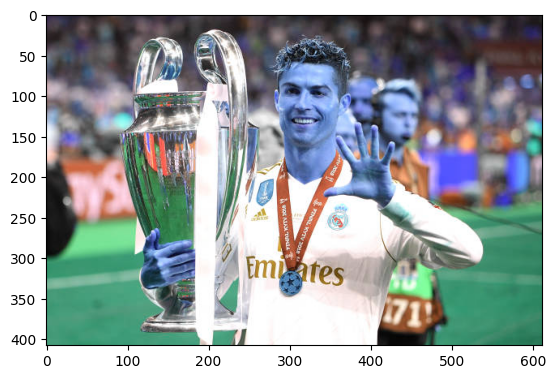

In [24]:
import matplotlib.pyplot as plt
plt.imshow(image)

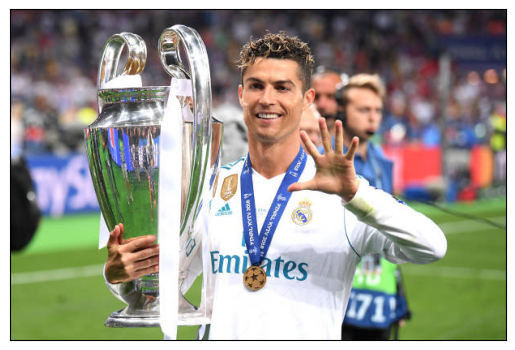

In [30]:
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
plt.xticks([])
plt.yticks([])
plt.imshow(image_rgb)
plt.show()

In [31]:
image[0]

array([[52, 42, 65],
       [52, 42, 65],
       [52, 41, 67],
       ...,
       [35, 32, 34],
       [38, 35, 37],
       [41, 38, 40]], shape=(612, 3), dtype=uint8)

array([[[ 52,  42,  65],
        [ 52,  42,  65],
        [ 52,  41,  67],
        ...,
        [ 35,  32,  34],
        [ 38,  35,  37],
        [ 41,  38,  40]],

       [[ 53,  43,  66],
        [ 53,  42,  68],
        [ 53,  42,  68],
        ...,
        [ 35,  32,  34],
        [ 38,  35,  37],
        [ 41,  38,  40]],

       [[ 54,  43,  69],
        [ 54,  43,  69],
        [ 54,  42,  70],
        ...,
        [ 37,  34,  36],
        [ 39,  36,  38],
        [ 42,  39,  41]],

       ...,

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]],

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]],

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]]], shape=(408, 612, 3), dtype=uint8)
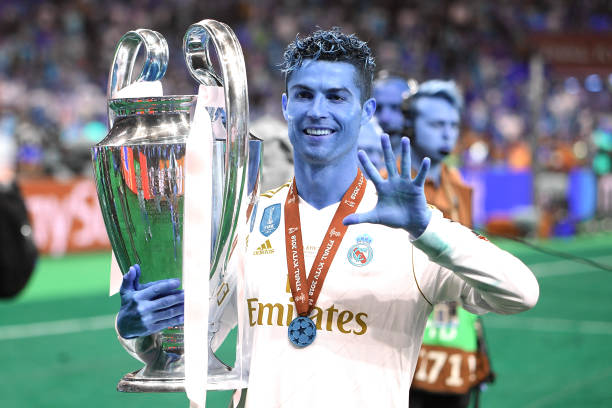

In [32]:
image

In [33]:
! pip install pydicom pillow numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 14.0 MB/s  0:00:00


In [34]:
import datetime
from PIL import Image
import numpy as np
import pydicom
from pydicom.dataset import FileDataset, FileMetaDataset
from pydicom.uid import ExplicitVRLittleEndian, SecondaryCaptureImageStorage


In [38]:

import datetime
from PIL import Image
import numpy as np
import pydicom

from pydicom.dataset import FileDataset, FileMetaDataset
from pydicom.uid import ExplicitVRLittleEndian, SecondaryCaptureImageStorage


def convert_to_dicom(image_path, output_dicom_path):

    # 1. Open image and convert to grayscale
    img = Image.open(image_path).convert("L")
    pixel_array = np.array(img).astype(np.uint16)

    # 2. Setup file meta-information
    file_meta = FileMetaDataset()
    file_meta.FileMetaInformationVersion = b"\x00\x01"
    file_meta.MediaStorageSOPClassUID = SecondaryCaptureImageStorage
    file_meta.MediaStorageSOPInstanceUID = pydicom.uid.generate_uid()
    file_meta.TransferSyntaxUID = ExplicitVRLittleEndian
    file_meta.ImplementationClassUID = pydicom.uid.generate_uid()

    # 3. Create the FileDataset instance
    ds = FileDataset(
        output_dicom_path,
        {},
        file_meta=file_meta,
        preamble=b"\x00" * 128
    )

    # 4. Populate Patient / Study Info
    ds.PatientName = "Anonymous^Patient"
    ds.PatientID = "123456"
    ds.PatientSex = "O"
    ds.PatientBirthDate = "19900101"

    # 5. Populate Study / Series metadata
    now = datetime.datetime.now()

    ds.StudyDate = now.strftime("%Y%m%d")
    ds.StudyTime = now.strftime("%H%M%S.%f")
    ds.StudyDescription = "Converted Standard Image"
    ds.Modality = "OT"
    ds.SeriesNumber = 1
    ds.InstanceNumber = 1

    # 6. Populate Image Pixel Module tags
    ds.SamplesPerPixel = 1
    ds.PhotometricInterpretation = "MONOCHROME2"

    ds.Rows, ds.Columns = pixel_array.shape

    ds.BitsAllocated = 16
    ds.BitsStored = 16
    ds.HighBit = 15
    ds.PixelRepresentation = 0

    # 7. Write raw binary pixel data
    ds.PixelData = pixel_array.tobytes()

    # 8. Save the dataset
    ds.is_little_endian = True
    ds.is_implicit_VR = False

    ds.save_as(output_dicom_path, enforce_file_format=True)

    print(f"Successfully saved: {output_dicom_path}")


# Example usage
convert_to_dicom(
    "/content/gettyimages-2279236241-612x612.jpg",
    "/content/output_image.dcm"
)


Successfully saved: /content/output_image.dcm


Patient Name...: Anonymous^Patient
Modality.......: OT
Study Date.....: 20261117
Image Size.....: 612 x 561


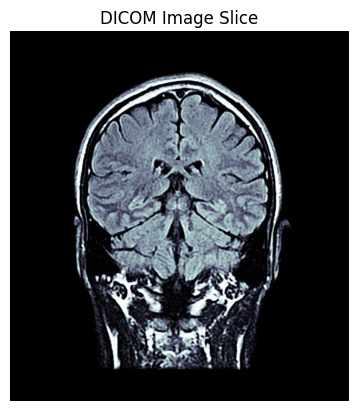

In [39]:
import matplotlib.pyplot as plt
import pydicom

# 1. Load the DICOM file
dicom_path = "output_image.dcm"
ds = pydicom.dcmread(dicom_path)

# 2. Access Metadata (DICOM Tags)
print(f"Patient Name...: {ds.PatientName}")
print(f"Modality.......: {ds.Modality}")
print(f"Study Date.....: {ds.StudyDate}")
print(f"Image Size.....: {ds.Rows} x {ds.Columns}")

# 3. Extract and display the pixel array
pixel_data = ds.pixel_array

plt.imshow(pixel_data, cmap=plt.cm.bone)
plt.title("DICOM Image Slice")
plt.axis("off")
plt.show()


In [40]:
pixel_data

array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], shape=(612, 561), dtype=uint16)

In [41]:
pixel_data.shape

(612, 561)

array([[[ 52,  42,  65],
        [ 52,  42,  65],
        [ 52,  41,  67],
        ...,
        [ 35,  32,  34],
        [ 38,  35,  37],
        [ 41,  38,  40]],

       [[ 53,  43,  66],
        [ 53,  42,  68],
        [ 53,  42,  68],
        ...,
        [ 35,  32,  34],
        [ 38,  35,  37],
        [ 41,  38,  40]],

       [[ 54,  43,  69],
        [ 54,  43,  69],
        [ 54,  42,  70],
        ...,
        [ 37,  34,  36],
        [ 39,  36,  38],
        [ 42,  39,  41]],

       ...,

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]],

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]],

       [[ 70, 156, 122],
        [ 70, 156, 122],
        [ 70, 156, 122],
        ...,
        [ 41, 120,  87],
        [ 41, 120,  87],
        [ 41, 120,  87]]], shape=(408, 612, 3), dtype=uint8)
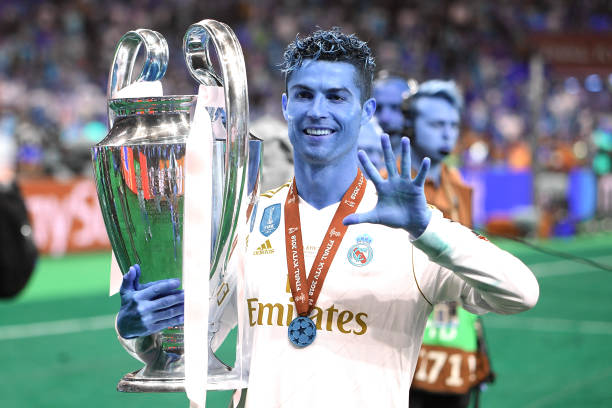

In [43]:
image

array([[ 50,  50,  50, ...,  33,  36,  39],
       [ 51,  51,  51, ...,  33,  36,  39],
       [ 52,  52,  52, ...,  35,  37,  40],
       ...,
       [136, 136, 136, ..., 101, 101, 101],
       [136, 136, 136, ..., 101, 101, 101],
       [136, 136, 136, ..., 101, 101, 101]], shape=(408, 612), dtype=uint8)
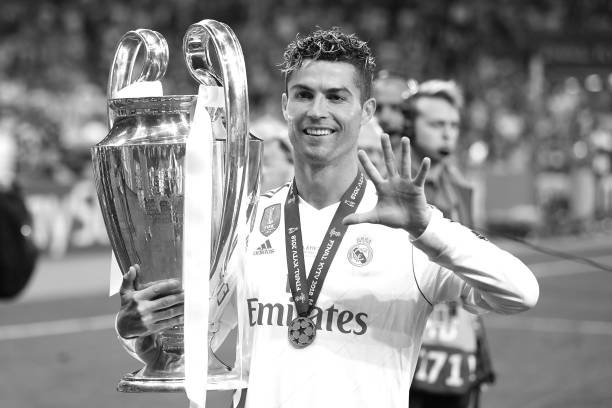

In [44]:
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
image_gray

In [45]:
image_gray.shape


(408, 612)

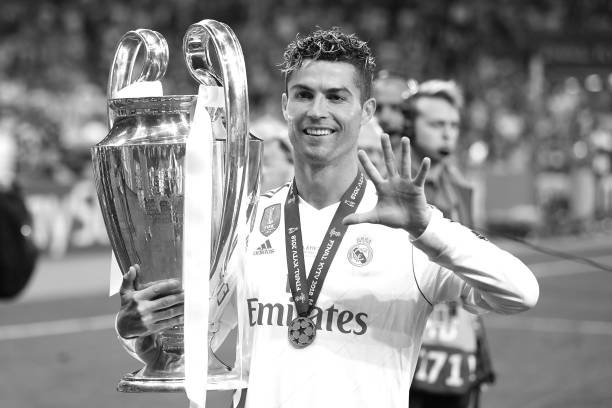

In [46]:
cv2_imshow(image_gray)

In [47]:
# Blur

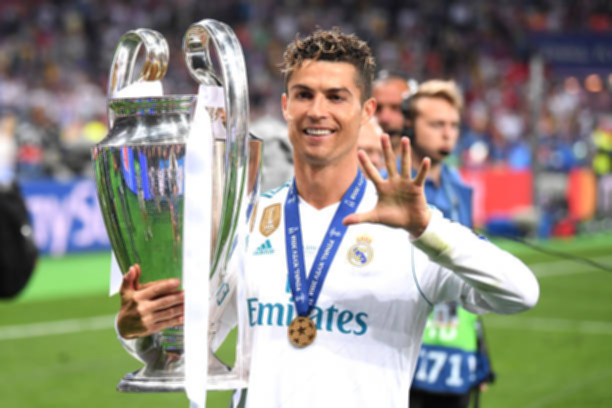

In [48]:
blured_image1 = cv.GaussianBlur(image, (3,3), cv.BORDER_DEFAULT)
cv2_imshow(blured_image1)

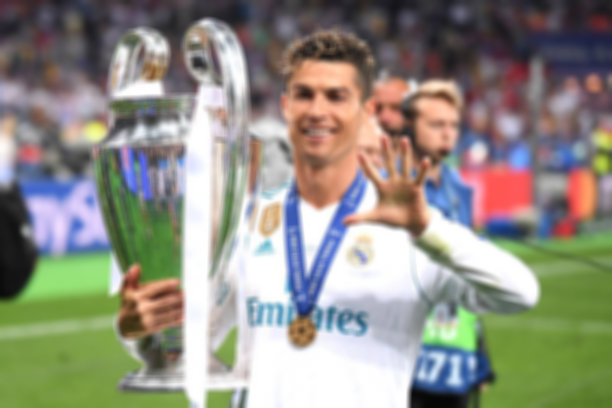

In [49]:
blured_image1 = cv.GaussianBlur(image, (7,7), cv.BORDER_DEFAULT)
cv2_imshow(blured_image1)

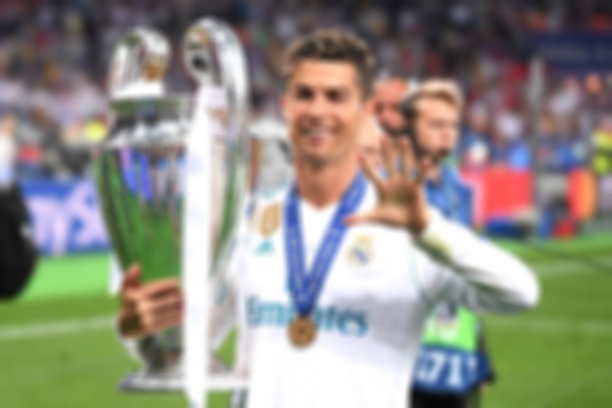

In [50]:
blured_image1 = cv.GaussianBlur(image, (11,11), cv.BORDER_DEFAULT)
cv2_imshow(blured_image1)

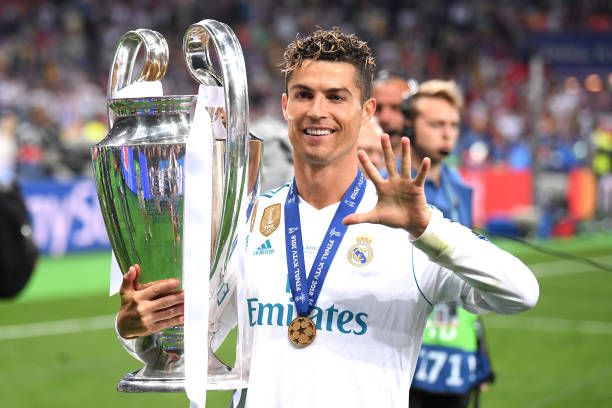

In [52]:
cv2_imshow(image)

In [53]:
image_copy = image.copy()

In [54]:
type(image_copy)

numpy.ndarray

In [55]:
np.info(image_copy)

class:  ndarray
shape:  (408, 612, 3)
strides:  (1836, 3, 1)
itemsize:  1
aligned:  True
contiguous:  True
fortran:  False
data pointer: 0x17c90cd0
byteorder:  little
byteswap:  False
type: uint8


In [56]:
np.info(image)

class:  ndarray
shape:  (408, 612, 3)
strides:  (1836, 3, 1)
itemsize:  1
aligned:  True
contiguous:  True
fortran:  False
data pointer: 0x17506a60
byteorder:  little
byteswap:  False
type: uint8


In [57]:
image_copy[ 0:  200 , 0 : 300 ] = cv.GaussianBlur(image_copy[ 0:  200 , 0 : 300 ], (11,11), cv.BORDER_DEFAULT)

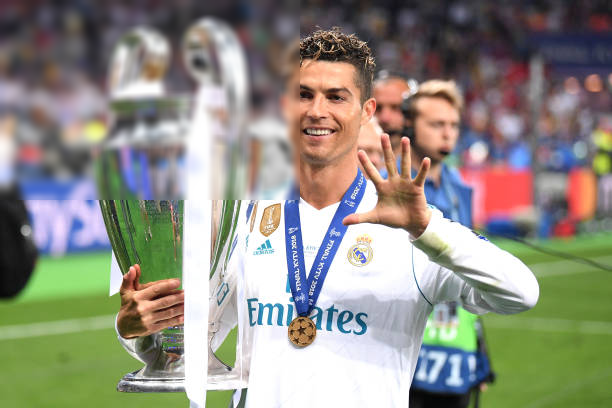

In [58]:
cv2_imshow(image_copy)

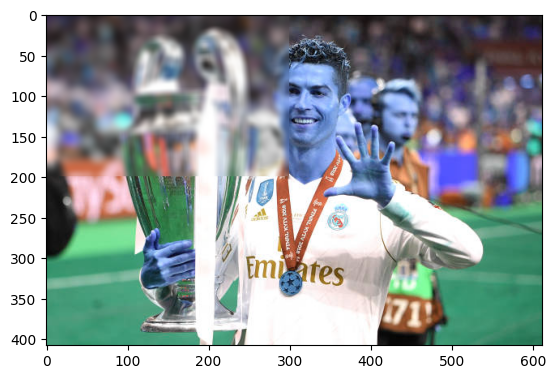

In [59]:
plt.imshow(image_copy )

In [60]:
image_copy[ 0:  500 , 380 : 650 ] = cv.GaussianBlur(image_copy[ 0:  500 , 380 : 650 ], (11,11), cv.BORDER_DEFAULT)

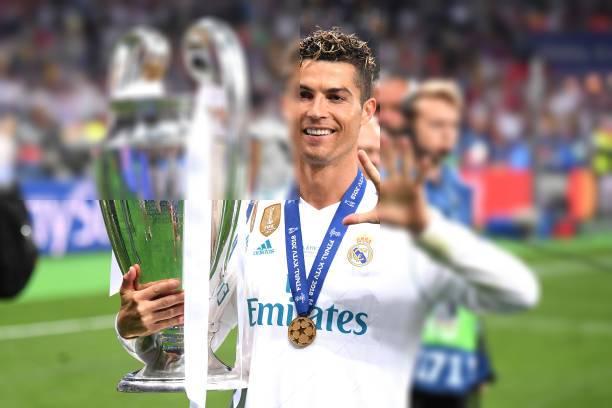

In [61]:
cv2_imshow(image_copy)

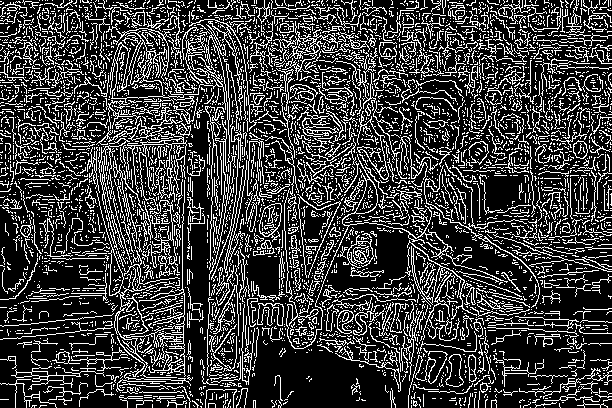

In [62]:
image_with_edges = cv.Canny(image, 10, 20 )
cv2_imshow(image_with_edges)

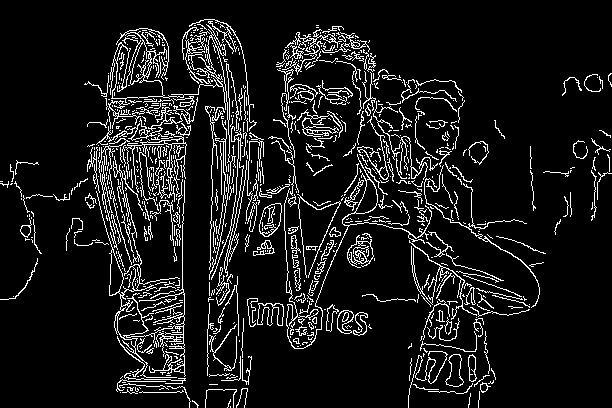

In [63]:
image_with_edges = cv.Canny(image, 100, 200 )
cv2_imshow(image_with_edges)

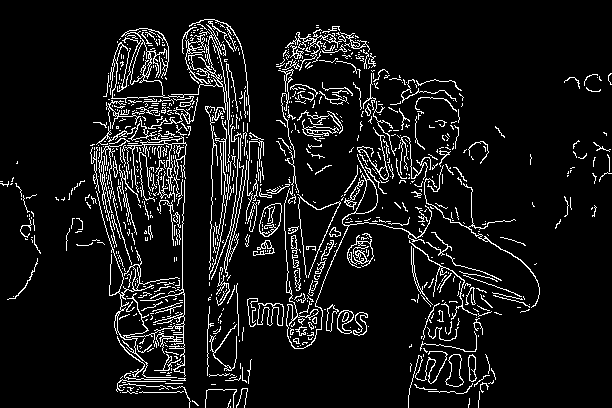

In [64]:
image_with_edges = cv.Canny(image, 160, 200 )
cv2_imshow(image_with_edges)


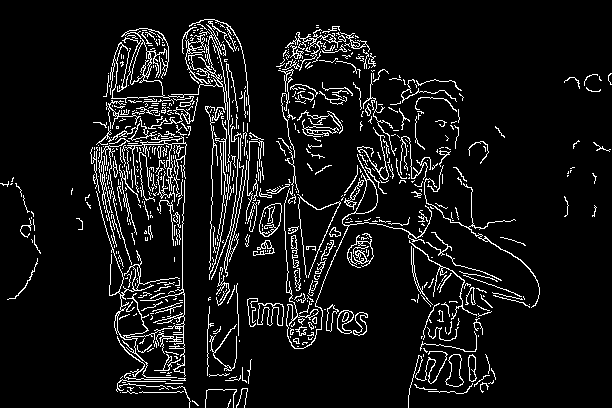

In [65]:
image_with_edges = cv.Canny(image, 160, 240 )
cv2_imshow(image_with_edges)

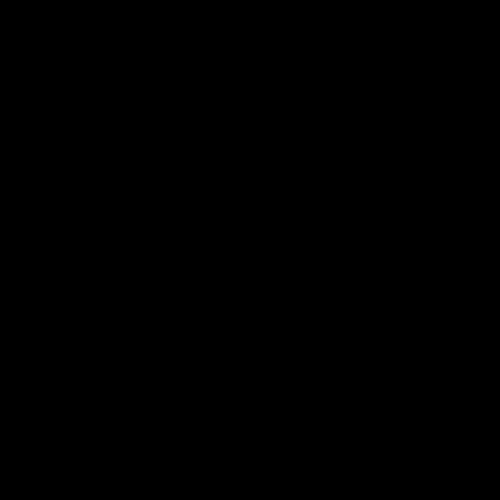

In [66]:
blank = np.zeros((500,500,3), dtype='uint8')
cv2_imshow(blank)

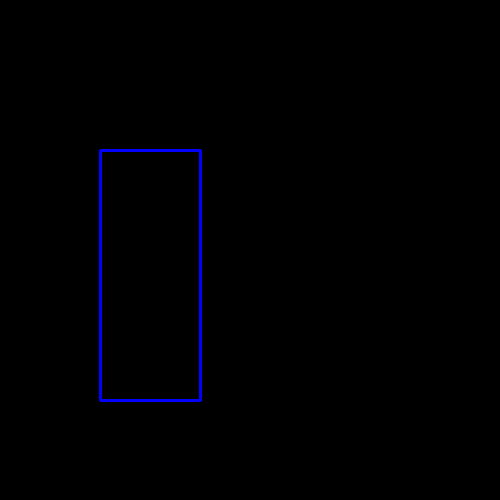

In [67]:
cv.rectangle(blank, (100,150),(200, 400), (255,0,0), thickness= 2 )
cv2_imshow(blank)

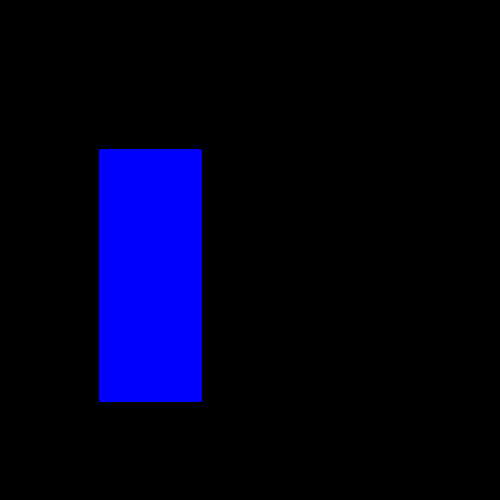

In [68]:
cv.rectangle(blank, (100,150),(200, 400), (255,0,0), thickness= -2 )
cv2_imshow(blank)

In [69]:
# Rotation
def rotate(img, angle, rotPoint=None):
    (height,width) = img.shape[:2]

    if rotPoint is None:
        rotPoint = (width//2,height//2)

    rotMat = cv.getRotationMatrix2D(rotPoint, angle, 1)
    dimensions = (width,height)

    return cv.warpAffine(img, rotMat, dimensions)

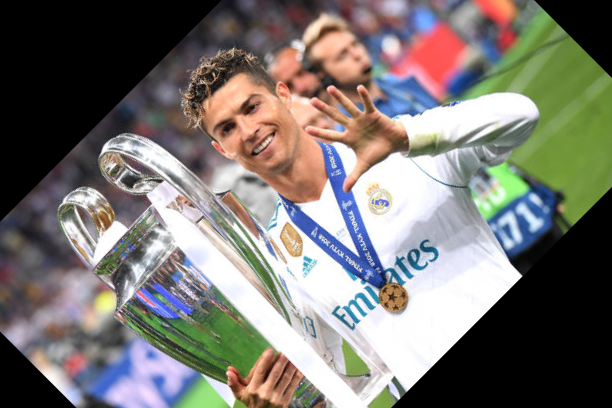

In [70]:
rotated = rotate(image, 45 )
cv2_imshow(rotated)

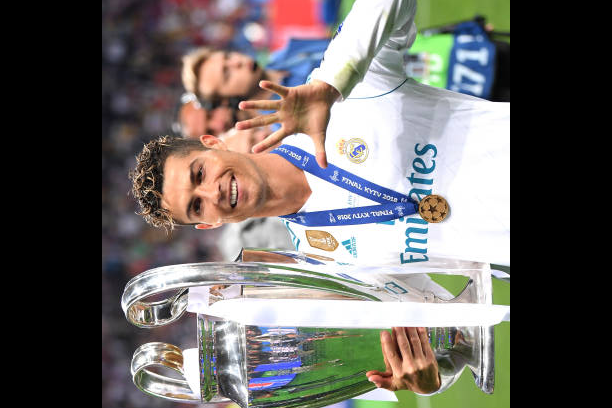

In [71]:
rotated = rotate(image, 90 )
cv2_imshow(rotated)

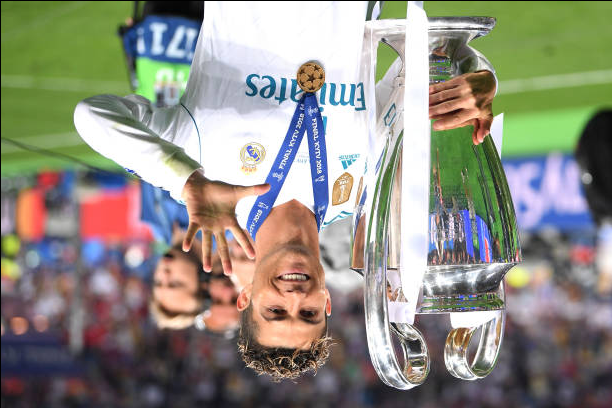

In [72]:
rotated = rotate(image, 180 )
cv2_imshow(rotated)

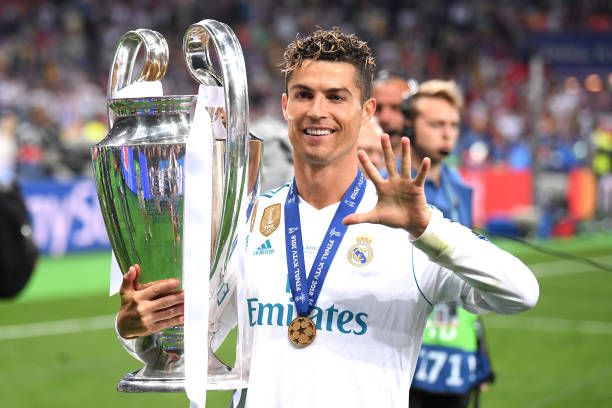

In [73]:
rotated = rotate(image, 360 )
cv2_imshow(rotated)

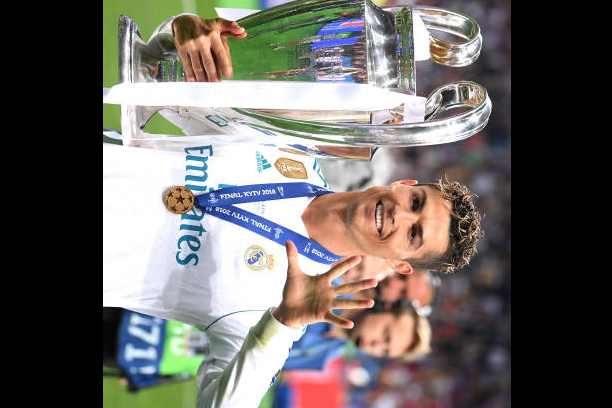

In [74]:
rotated = rotate(image, 270 )
cv2_imshow(rotated)

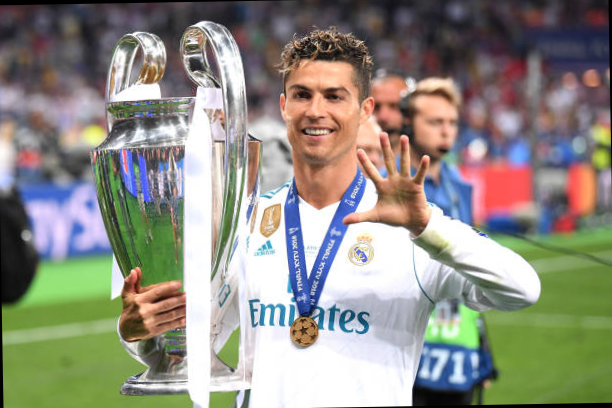

In [76]:
rotated = rotate(image, 1)
cv2_imshow(rotated)

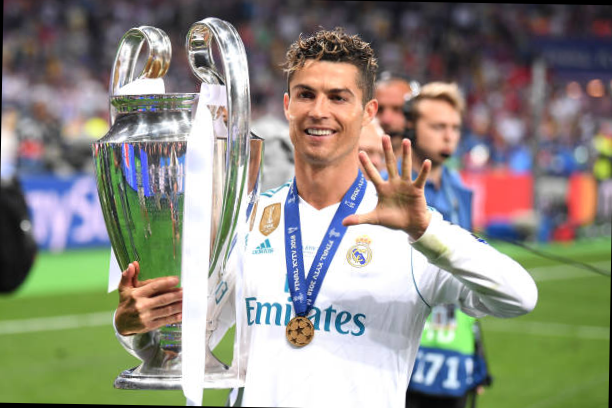

In [77]:
rotated = rotate(image, -1 )
cv2_imshow(rotated)